# Settings

In [22]:
file_paths = [
    # "./data_nsi/csv/beamformed/004_veins_crossed_rectangle.npy",
    # "./data_nsi/csv/beamformed/004_veins_crossed_env_nsi.npy",
    # "./data_nsi/csv/beamformed/005_veins_crossed_frames_test_rectangle.npy",
    # "./data_nsi/csv/beamformed/005_veins_crossed_frames_test_env_nsi.npy",
    "./data_nsi/csv/beamformed/005_veins_crossed_frames_test_env_nsi.npy",
]

parameters_file_path = "./parameters/003_simulation_test.json"

visualizing_upsampled_data = True

# Imports

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [24]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [25]:
def add_extra_params(params, C):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    samples = params["rf"]["samples"] if not visualizing_upsampled_data else params["rf"]["upsampled_samples"]
    sampling_rate = params["rf"]["sampling_rate"] if not visualizing_upsampled_data else params["rf"]["upsampled_sampling_rate"]

    max_acquisition_depth = C * (1 / sampling_rate * samples) / 2
    params["image"]["samples_depth"] = int(max_acquisition_depth / params["image"]["dz"])
    params["image"]["samples_lateral"] = int(params["array"]["length"] * params["array"]["pitch"] / params["image"]["dx"])

    return params

In [26]:
C = 1500 #speed of sound

params = load_parameters(parameters_file_path)
params = add_extra_params(params, C)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling

# Import bf image data

C:\Users\Acer\AppData\Local\Temp\ipykernel_24648\197755850.py:53: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


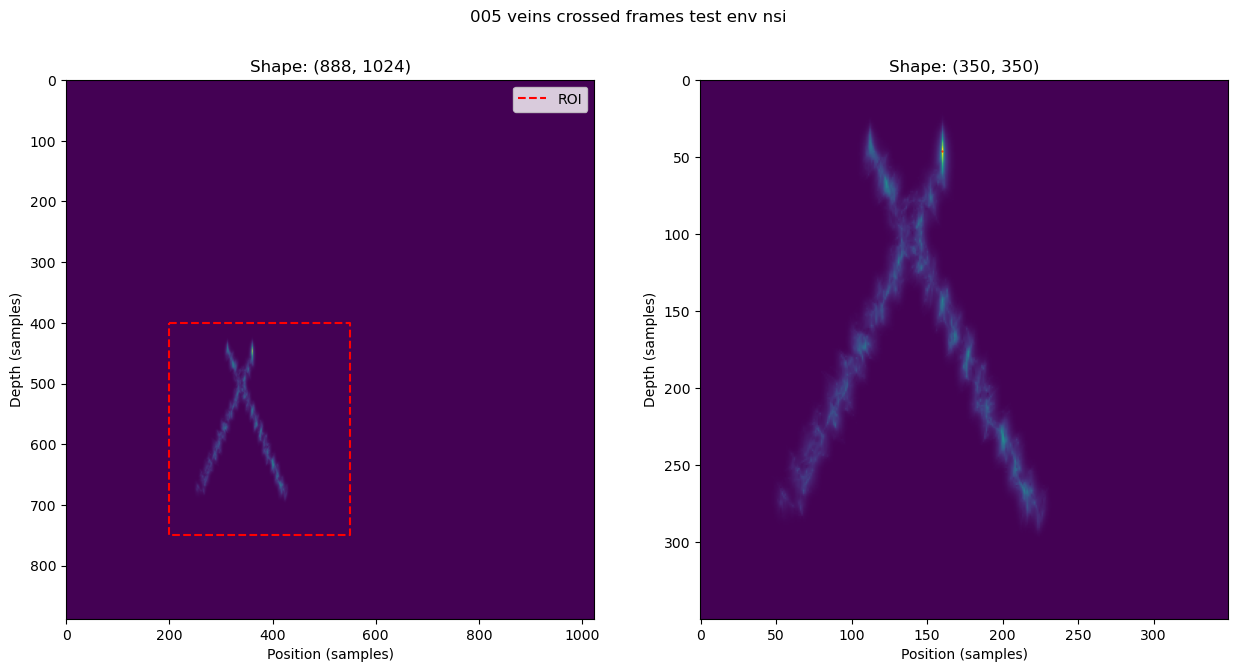

In [ ]:
bf_matrices = np.zeros(
        (
        params["image"]["nz"] if params["image"]["nz"] != None else params["image"]["samples_depth"],
        params["image"]["nx"] if params["image"]["nx"] != None else params["image"]["samples_lateral"], 
        len(file_paths)
        )
    )
labels = []

for idx, file_path in enumerate(file_paths):

    x0 = params["image"]["x0"]
    z0 = params["image"]["z0"]
    nx = params["image"]["nx"]
    nz = params["image"]["nz"]

    sub_plot_size = 1 if nx == None or nz == None else 2

    fig, ax = plt.subplots(1, sub_plot_size, figsize=(15, 7))

    if sub_plot_size == 1:
        ax = [ax]
    
    data = np.load(file_path)

    ax[0].imshow(np.abs(data), aspect='auto', cmap='viridis')
    ax[0].set_xlabel("Position (samples)")
    ax[0].set_ylabel("Depth (samples)")
    ax[0].set_title(f"Shape: {data.shape}")

    if nx != None and nz != None:
    #box around the xo, zo, nx, nz
        ax[0].plot([x0, x0+nx, x0+nx, x0, x0], [z0, z0, z0+nz, z0+nz, z0], 'r--', label='ROI')
        ax[0].legend()

        data = data[z0:z0+nz, x0:x0+nx]

        max_row, max_col = np.unravel_index(np.argmax(np.abs(data)), data.shape)

        ax[1].imshow(np.abs(data), aspect='auto', cmap='viridis')
        ax[1].set_xlabel("Position (samples)")
        ax[1].set_ylabel("Depth (samples)")
        ax[1].set_title(f"Shape: {data.shape}")  

        #show max energy point
        ax[1].scatter(max_col, max_row, color='red', s=0.2)

    bf_matrices[:, :, idx] = data
    label = file_path.strip().split("/")[-1].split(".")[0].replace("_", " ")
    labels.append(label)

    fig.suptitle(label)
    fig.show()

# Get high energy zone

In [28]:
def extract_highest_value_region_for_all(bf_matrices, depth_margin=15, lateral_margin=15):
    submatrices = []
    low_row_pos = np.inf
    high_row_pos = -np.inf
    low_col_pos = np.inf
    high_col_pos = -np.inf
    
    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        if row < low_row_pos:
            low_row_pos = row
        if row > high_row_pos:
            high_row_pos = row
        if col < low_col_pos:
            low_col_pos = col
        if col > high_col_pos:
            high_col_pos = col

    submatrices = bf_matrices[low_row_pos-depth_margin:high_row_pos+depth_margin, low_col_pos-lateral_margin:high_col_pos+lateral_margin, :]
    return submatrices

In [29]:
def extract_highest_value_region(bf_matrices, submatrix_size=100):
    submatrices = []

    for i in range(bf_matrices.shape[2]):
        row, col = np.unravel_index(np.argmax(np.abs(bf_matrices[:,:,i])), bf_matrices[:,:,i].shape)

        half_size = int(submatrix_size/2)
        row_start = row - half_size if row - half_size >= 0 else 0
        row_end = row + half_size if row + half_size < bf_matrices.shape[0] else bf_matrices.shape[0]
        col_start = col - half_size if col - half_size >= 0 else 0
        col_end = col + half_size if col + half_size < bf_matrices.shape[1] else bf_matrices.shape[1]

        submatrices.append(bf_matrices[row_start:row_end, col_start:col_end, i])
        
    return submatrices

In [30]:
submatrices_standalone = extract_highest_value_region(bf_matrices, submatrix_size=50)

# Visualize lobes and resolution

In [31]:
def calculate_resolution(function):
    half_max = -6 #dB
    left_idx = np.where(function >= half_max)[0][0] #first point where the profile is greater than half max
    right_idx = np.where(function >= half_max)[0][-1] #last point where the profile is greater than half max
    return left_idx, right_idx, right_idx - left_idx

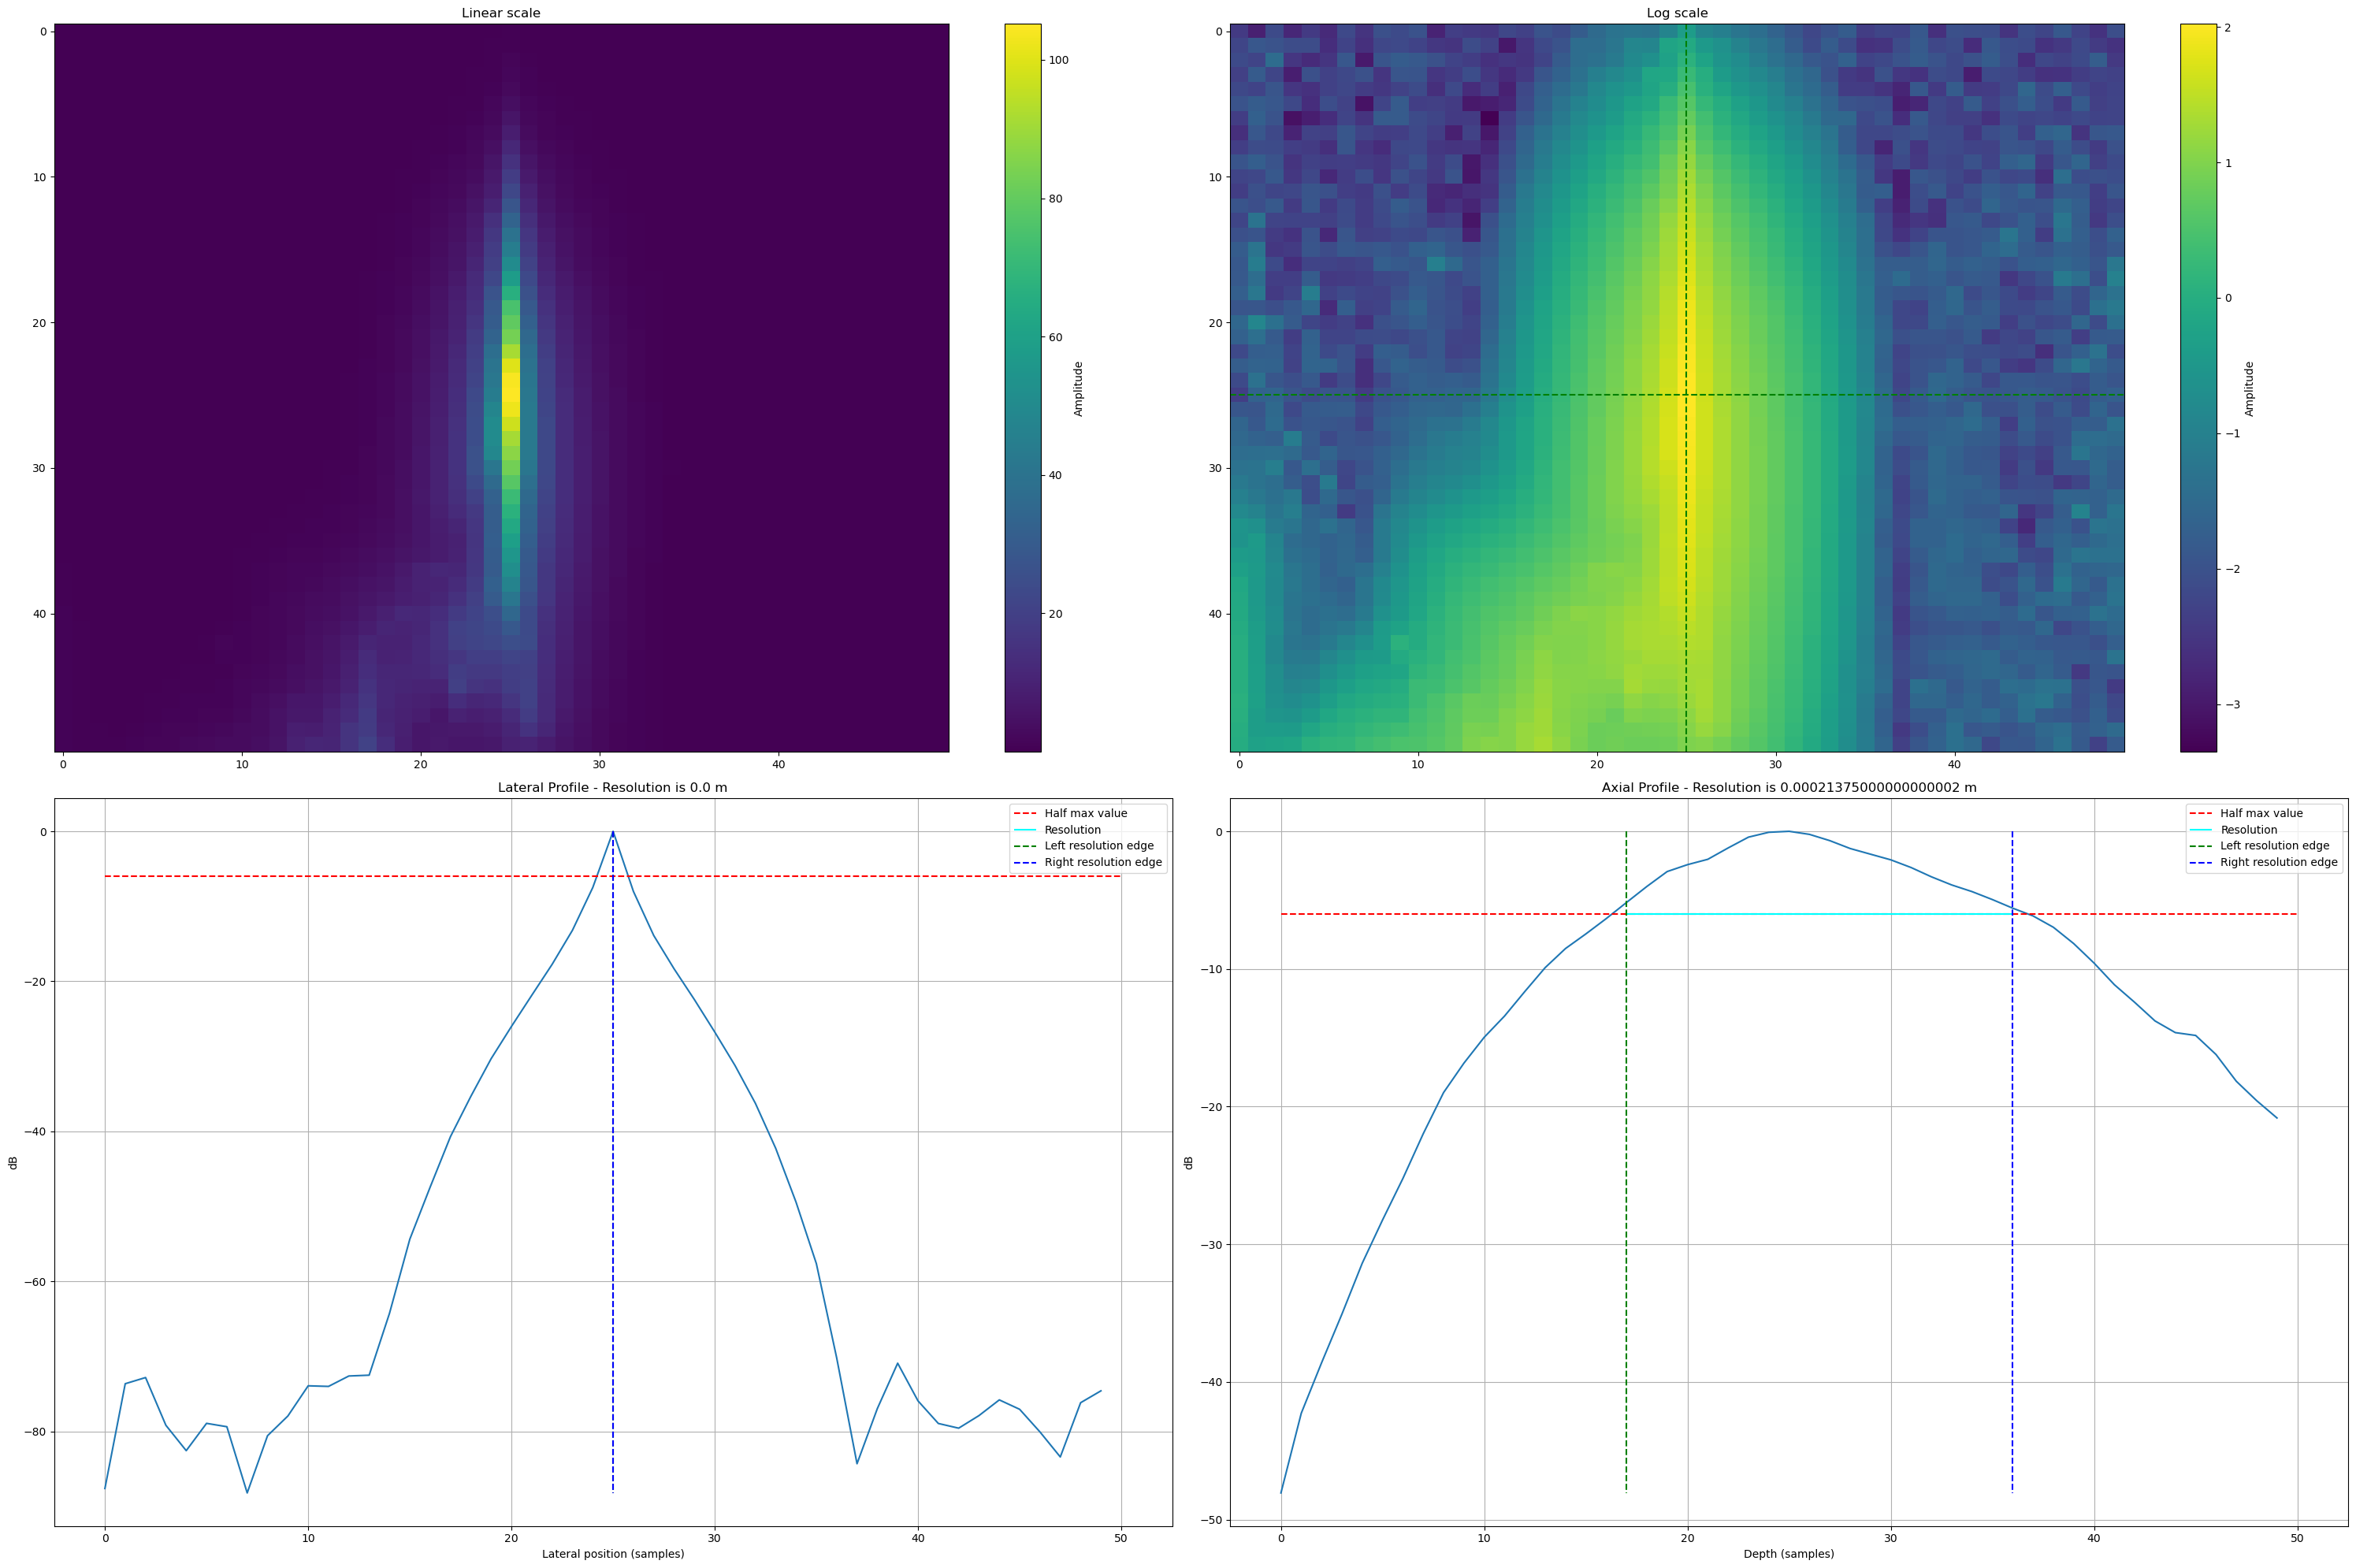

In [32]:
for idx, submatrix in enumerate(submatrices_standalone):
    
    max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix)), submatrix.shape) #max value position

    fig, ax = plt.subplots(2,2, figsize=(30, 20))

    # visulization of high energy zone
    im0 = ax[0,0].imshow(np.abs(submatrix), cmap='viridis', aspect='auto')
    ax[0,0].set_title("Linear scale")
    plt.colorbar(im0, label="Amplitude", ax=ax[0,0])

    #log view of high energy zone 
    im1 = ax[0,1].imshow(np.log10(np.abs(submatrix)), cmap='viridis', aspect='auto')
    ax[0,1].set_title("Log scale")
    ax[0,1].axhline(y=max_val_row, color='g', linestyle='--')
    ax[0,1].axvline(x=max_val_col, color='g', linestyle='--')
    plt.colorbar(im1, label="Amplitude", ax=ax[0,1])

    #visualization of lateral profile (Lateral res (horizontal))
    lateral_profile =  20 * np.log10(np.abs(submatrix[max_val_row, :]) / np.max(np.abs(submatrix[max_val_row, :]))) #we take values along the row with maximum value

    lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)

    im2 = ax[1,0].plot(lateral_profile)
    ax[1,0].set_title(f"Lateral Profile - Resolution is {lat_res * params['image']['dx']} m")
    ax[1,0].set_xlabel("Lateral position (samples)")
    ax[1,0].set_ylabel("dB")
    ax[1,0].grid(True)
    ax[1,0].hlines(-6, 0, lateral_profile.shape[0], color='r', linestyle='--', label='Half max value')
    ax[1,0].hlines(-6, lat_left_idx, lat_right_idx, color='cyan', linestyle='-', label=f'Resolution')
    ax[1,0].vlines(lat_left_idx, 0, min(lateral_profile), color='g', linestyle='--', label='Left resolution edge')
    ax[1,0].vlines(lat_right_idx, 0, min(lateral_profile), color='b', linestyle='--', label='Right resolution edge')
    ax[1,0].legend()

    #visulization of axial resolution (vertical)
    axial_profile = 20 * np.log10(np.abs(submatrix[:, max_val_col]) / np.max(np.abs(submatrix[:, max_val_col]))) #we take values along the column with maximum value

    ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)

    im3 = ax[1,1].plot(axial_profile)
    ax[1,1].set_title(f"Axial Profile - Resolution is {ax_res * params["image"]["dz"]} m")
    ax[1,1].set_xlabel("Depth (samples)")
    ax[1,1].set_ylabel("dB")
    ax[1,1].grid(True)
    ax[1,1].hlines(-6, 0, axial_profile.shape[0], color='r', linestyle='--', label='Half max value')
    ax[1,1].hlines(-6, ax_left_idx, ax_right_idx, color='cyan', linestyle='-', label=f'Resolution')
    ax[1,1].vlines(ax_left_idx, 0, min(axial_profile), color='g', linestyle='--', label='Left resolution edge')
    ax[1,1].vlines(ax_right_idx, 0, min(axial_profile), color='b', linestyle='--', label='Right resolution edge')
    ax[1,1].legend()

    plt.tight_layout()
    plt.show()

# Comparaison

In [33]:
def compare_resolutions(bf_matrices, step_size, lateral_step, labels, depth_margin=15, lateral_margin=15, ymin=None, ymax=None, xmin=None, xmax=None):
    submatrix = extract_highest_value_region_for_all(np.abs(bf_matrices), depth_margin= depth_margin, lateral_margin= lateral_margin)
    
    #viz
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    axes[0].hlines(-6, 0, 0,colors='r', linestyles='--', label='Half max value (-6dB)')
    axes[1].hlines(-6, 0, 0, colors='r', linestyles='--', label='Half max value (-6dB)')


    for i in range(submatrix.shape[2]):
        
        max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(submatrix[:,:,i])), submatrix[:,:,i].shape)

        lateral_profile = 20 * np.log10(np.abs(submatrix[:,:,i][max_val_row, :]) / np.max(np.abs(submatrix[:,:,i][max_val_row, :])))
        axial_profile = 20 * np.log10(np.abs(submatrix[:,:,i][:, max_val_col]) / np.max(np.abs(submatrix[:,:,i][:, max_val_col])))

        #calculate resolutions
        lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)
        
        ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)
        
        #convert resolutions to meters
        lat_res_m = lat_res * lateral_step
        
        ax_res_m = ax_res * step_size
        
        #plot lateral profiles
        axes[0].plot(lateral_profile, label=f"{labels[i]} - {lat_res_m} m")
        axes[0].set_title("Lateral Profiles Comparison")
        axes[0].set_xlabel("Lateral position (samples)")
        axes[0].set_ylabel("Amplitude (dB)")
        axes[0].grid(True)
        axes[0].hlines(-6, 0, lateral_profile.shape[0], colors='r', linestyles='--')
        axes[0].set_ylim(ymin, ymax)
        axes[0].set_xlim(xmin, xmax)
        axes[0].legend()
        
        #plot axial profiles
        axes[1].plot(axial_profile, label=f"{labels[i]} - {ax_res_m} m")
        axes[1].set_title("Axial Profiles Comparison")
        axes[1].set_xlabel("Depth (samples)")
        axes[1].set_ylabel("Amplitude (dB)")
        axes[1].grid(True)
        axes[1].hlines(-6, 0, axial_profile.shape[0], colors='r', linestyles='--')
        axes[1].set_ylim(ymin, ymax)
        axes[1].legend()
        
    plt.tight_layout()
    plt.show()

In [34]:
bf_matrices.shape

(350, 350, 1)

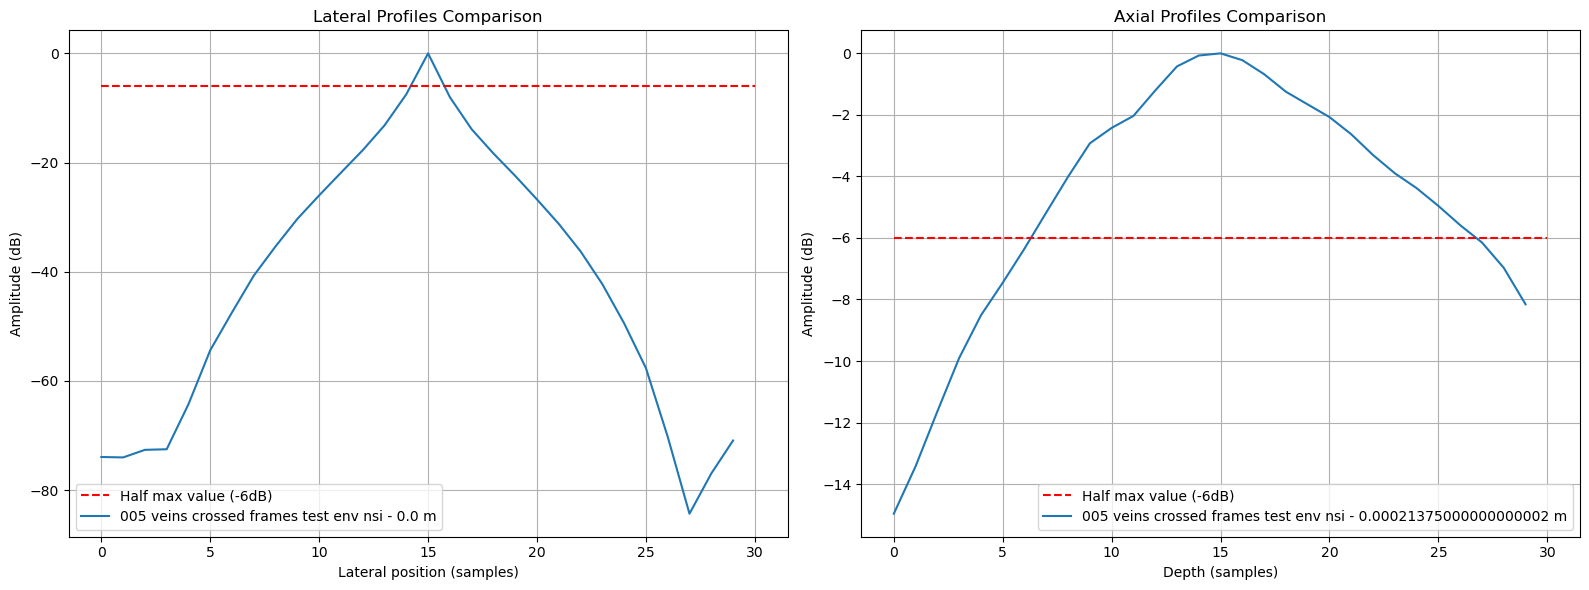

In [35]:
compare_resolutions(bf_matrices, params["image"]["dz"], params["image"]["dx"], labels)